# Experiment 5 — Biomedical Signal Processing on PCG Dataset

**Course:** Signal Processing and Systems Design Laboratory (EE69205)  
**Dataset:** Modified PhysioNet PCG data (`heartSoundData.mat`)  
**Sampling frequency:** `fs = 2000 Hz`  

This notebook performs EDA on the PCG dataset, removes outlier samples (|value| > 3× std), and carries out all denoising/filtering tasks listed in the lab manual (items i–viii), computing Reconstruction SNR (RSNR) for each.

Data fields:
- `Data`: 10,000 × 3,829 matrix — each column is one PCG recording (first 10,000 samples at 2 kHz)
- `Classes`: 3,829 × 1 categorical labels (normal / abnormal)

In [ ]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from scipy.signal import medfilt, firwin, filtfilt, butter, sosfiltfilt
from scipy.signal.windows import gaussian
from scipy.ndimage import convolve1d, uniform_filter1d
from IPython.display import display, HTML

# ---------------------------------------------------------------- #
# 1. Load the MATLAB data file
# ---------------------------------------------------------------- #
mat = sio.loadmat('../heartSoundData.mat')
sd = mat['heartSoundData'][0, 0]
Data = sd['Data']          # (10000, 3829) float64 — each column = one PCG record
Classes = sd['Classes']    # categorical labels (opaque from scipy)

fs = 2000                  # Hz (per manual)
n_samples, n_records = Data.shape
t = np.arange(n_samples) / fs   # time axis in seconds

print('Data shape  :', Data.shape)
print('Classes shape:', Classes.shape)
print('fs          :', fs, 'Hz')
print('n_records   :', n_records)
print('Record length:', n_samples, 'samples = %.3f s' % (n_samples / fs))
print()
print('Global stats over all records:')
print('  min   = %.6f' % Data.min())
print('  max   = %.6f' % Data.max())
print('  mean  = %.6f' % Data.mean())
print('  std   = %.6f' % Data.std())
print('  NaN   :', bool(np.isnan(Data).any()), '| Inf:', bool(np.isinf(Data).any()))

# Class distribution (best-effort; MATLAB categorical is opaque via scipy)
try:
    vals, counts = np.unique(Classes.ravel(), return_counts=True)
    print()
    print('Unique class codes:', vals.tolist())
    print('Class counts     :', counts.tolist())
except Exception as e:
    print()
    print('(Class distribution could not be decoded from opaque categorical:', e, ')')


Data shape  : (10000, 3829)
Classes shape: (1,)
fs          : 2000 Hz
n_records   : 3829
Record length: 10000 samples = 5.000 s

Global stats over all records:
  min   = -1.000000
  max   = 1.000000
  mean  = -0.021066


  std   = 0.129450
  NaN   : False | Inf: False

Unique class codes: [('MCOS', 'categorical', array([[3707764736],
       [         2],
       [         1],
       [         1],
       [         1],
       [         1]], dtype=uint32))]
Class counts     : [1]


x(t) stats:
  min   = -0.112396
  max   = 1.000000
  mean  = 0.009738
  std   = 0.100587


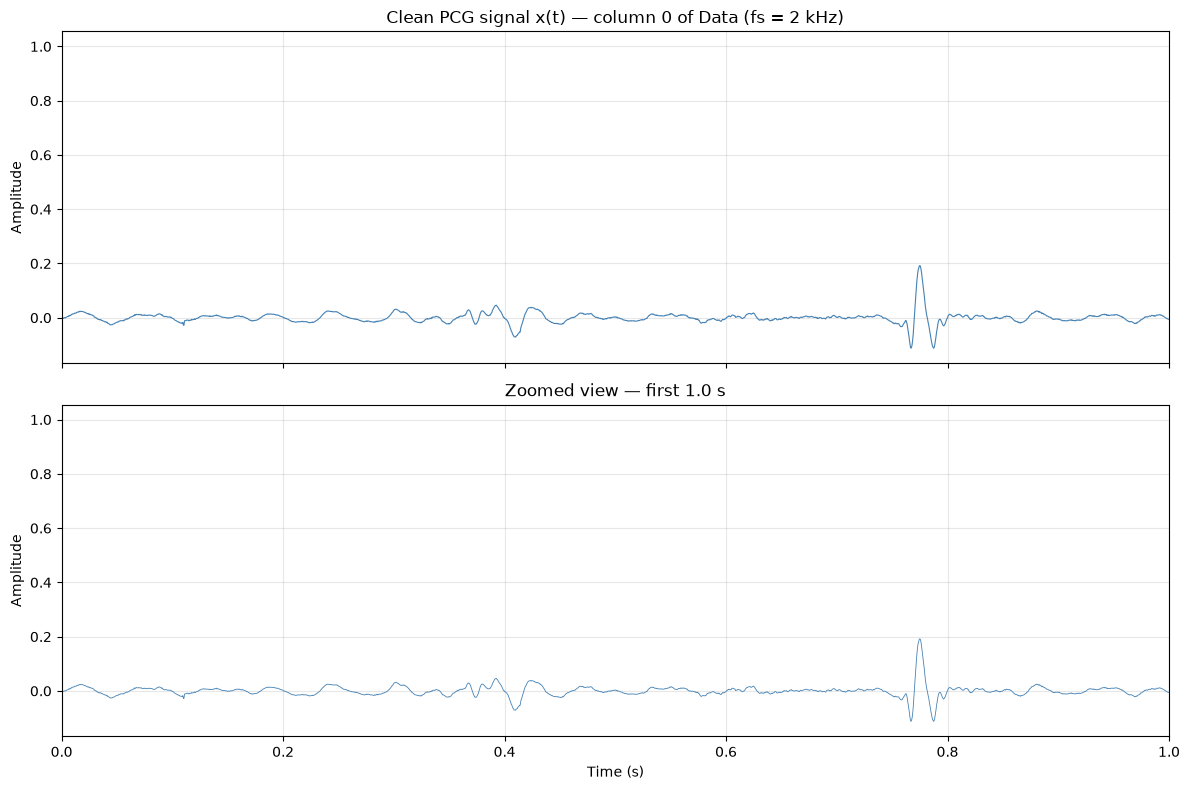


Spike/outlier check on x(t):
  mean  = 0.009738
  std   = 0.100587
  threshold (|x-mean| > 3*std) = 0.301762
  # samples beyond threshold   = 98  (0.980% of samples)


In [ ]:
# ---------------------------------------------------------------- #
# Task i: EDA — Plot clean PCG signal x(t) = first column of Data
# ---------------------------------------------------------------- #
x = Data[:, 0].astype(np.float64).copy()   # clean signal x(t)

print('x(t) stats:')
print('  min   = %.6f' % x.min())
print('  max   = %.6f' % x.max())
print('  mean  = %.6f' % x.mean())
print('  std   = %.6f' % x.std())

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax[0].plot(t, x, color='steelblue', lw=0.8)
ax[0].set_title('Clean PCG signal x(t) — column 0 of Data (fs = 2 kHz)', fontsize=12)
ax[0].set_ylabel('Amplitude')
ax[0].grid(True, alpha=0.3)

ax[1].plot(t, x, color='steelblue', lw=0.6)
ax[1].set_xlim(0, 1.0)   # zoom into first 1 s to inspect morphology / spikes
ax[1].set_title('Zoomed view — first 1.0 s')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Amplitude')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Spike-type noise check: samples beyond 3*std from mean
mean_x = x.mean()
std_x = x.std()
spike_mask = np.abs(x - mean_x) > 3 * std_x
n_spikes = int(spike_mask.sum())
print()
print('Spike/outlier check on x(t):')
print('  mean  = %.6f' % mean_x)
print('  std   = %.6f' % std_x)
print('  threshold (|x-mean| > 3*std) = %.6f' % (3 * std_x))
print('  # samples beyond threshold   =', n_spikes, ' (%.3f%% of samples)' % (100*n_spikes/len(x)))


Outliers detected (|x - mean| > 3*std): 98 samples
After cleaning:
  min   = -0.112396
  max   = 0.192078
  mean  = -0.000089
  std   = 0.020319
  beyond 3*std now : 206


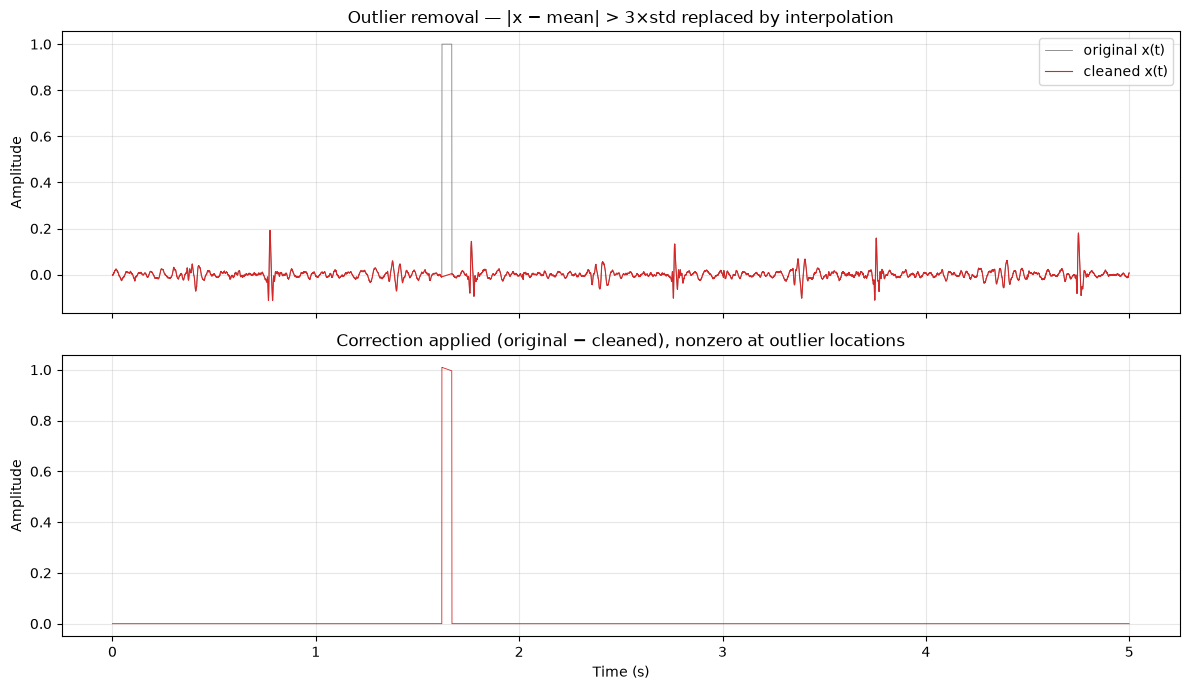

In [ ]:
# ---------------------------------------------------------------- #
# Outlier removal: remove samples with |x - mean| > 3 * std
# We replace them via linear interpolation so x(t) stays continuous
# for the downstream filtering steps.
# ---------------------------------------------------------------- #
x_clean = x.copy()
outlier_mask = np.abs(x - mean_x) > 3 * std_x
n_outliers = int(outlier_mask.sum())
print('Outliers detected (|x - mean| > 3*std):', n_outliers, 'samples')

if n_outliers > 0:
    idx = np.arange(len(x))
    good = ~outlier_mask
    # interpolate outliers using the good samples
    x_clean[outlier_mask] = np.interp(idx[outlier_mask], idx[good], x[good])

# Verify
print('After cleaning:')
print('  min   = %.6f' % x_clean.min())
print('  max   = %.6f' % x_clean.max())
print('  mean  = %.6f' % x_clean.mean())
print('  std   = %.6f' % x_clean.std())
print('  beyond 3*std now :', int((np.abs(x_clean - x_clean.mean()) > 3*x_clean.std()).sum()))

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(t, x, color='gray', lw=0.6, label='original x(t)')
ax[0].plot(t, x_clean, color='tab:red', lw=0.8, label='cleaned x(t)')
ax[0].set_title('Outlier removal — |x − mean| > 3×std replaced by interpolation')
ax[0].set_ylabel('Amplitude')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(t, x - x_clean, color='tab:red', lw=0.6)
ax[1].set_title('Correction applied (original − cleaned), nonzero at outlier locations')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Amplitude')
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Use cleaned signal as the reference "clean" signal for the rest of the experiment
x = x_clean


In [ ]:
# ---------------------------------------------------------------- #
# Noise model & RSNR helper
# ---------------------------------------------------------------- #
def add_white_gaussian_noise(signal, snr_db, fs=2000, seed=0):
    """Add white Gaussian noise w(t) to achieve target SNR (dB)."""
    rng = np.random.default_rng(seed)
    x = np.asarray(signal, dtype=np.float64)
    p_signal = np.mean(x ** 2)
    if p_signal <= 0:
        p_signal = np.var(x)
    p_noise = p_signal / (10 ** (snr_db / 10.0))
    w = rng.normal(0.0, np.sqrt(p_noise), size=x.shape)
    y = x + w
    return y, w

def rsnr_db(original, reconstructed):
    """Reconstruction SNR (dB) = 10*log10( sum(x^2) / sum((x - xr)^2) )."""
    x = np.asarray(original, dtype=np.float64)
    xr = np.asarray(reconstructed, dtype=np.float64)
    num = np.sum(x ** 2)
    den = np.sum((x - xr) ** 2)
    if den <= 0:
        return np.inf
    return 10.0 * np.log10(num / den)

print('Helpers defined: add_white_gaussian_noise(signal, snr_db), rsnr_db(orig, recon)')
print('Target SNR levels (manual item vii): 5, 10, 15 dB')


Helpers defined: add_white_gaussian_noise(signal, snr_db), rsnr_db(orig, recon)
Target SNR levels (manual item vii): 5, 10, 15 dB


Default SNR target  : 10 dB
Actual SNR achieved : 9.95 dB
y(t) stats — min -0.120447 max 0.192696 mean -0.000155 std 0.021404


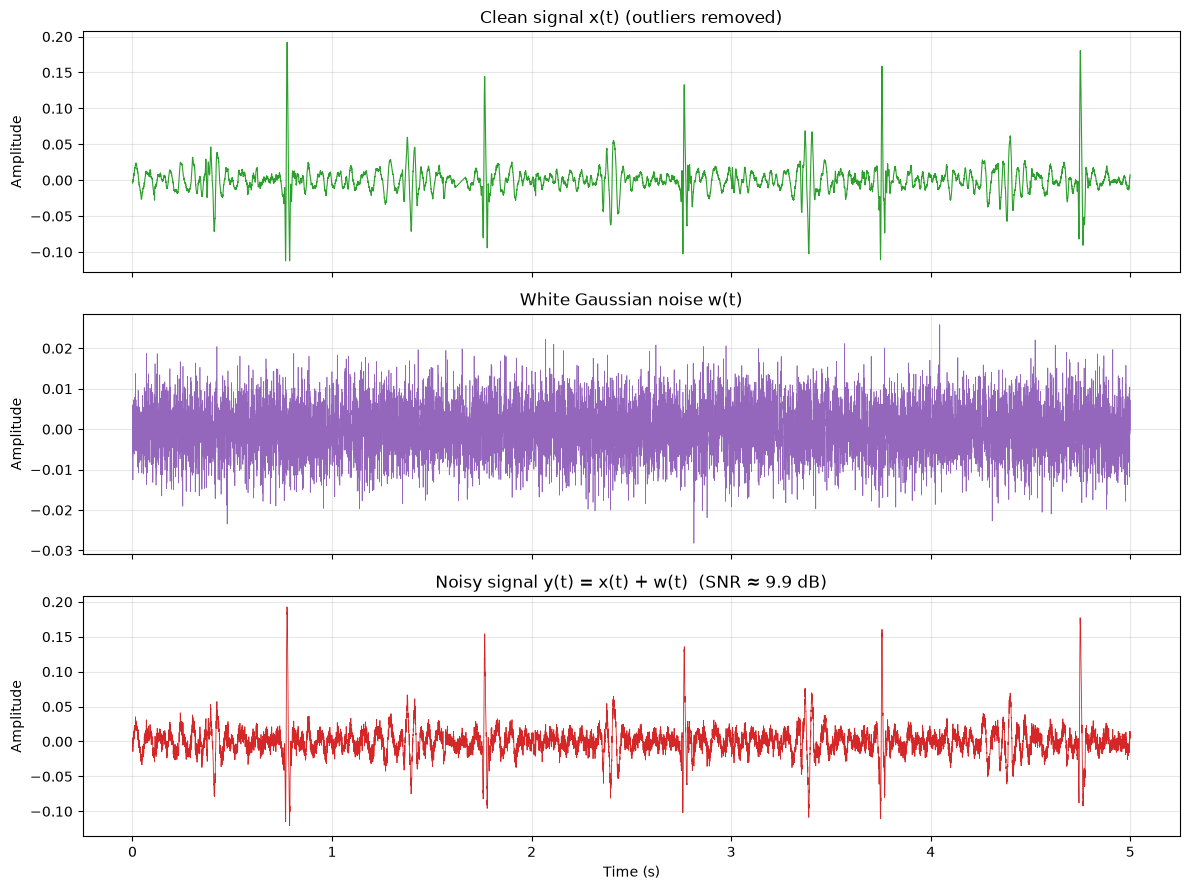

In [ ]:
# ---------------------------------------------------------------- #
# Task i (cont.): Generate white Gaussian noise w(t), noisy y(t)=x+w
# Use SNR = 10 dB as the default working level; item vii repeats at 5/15 dB.
# ---------------------------------------------------------------- #
snr_default = 10
y, w = add_white_gaussian_noise(x, snr_default, seed=42)
actual_snr = 10*np.log10(np.mean(x**2)/np.mean(w**2))
print('Default SNR target  :', snr_default, 'dB')
print('Actual SNR achieved : %.2f dB' % actual_snr)
print('y(t) stats — min %.6f max %.6f mean %.6f std %.6f' % (y.min(), y.max(), y.mean(), y.std()))

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(t, x, color='tab:green', lw=0.8)
ax[0].set_title('Clean signal x(t) (outliers removed)')
ax[0].set_ylabel('Amplitude'); ax[0].grid(True, alpha=0.3)

ax[1].plot(t, w, color='tab:purple', lw=0.5)
ax[1].set_title('White Gaussian noise w(t)')
ax[1].set_ylabel('Amplitude'); ax[1].grid(True, alpha=0.3)

ax[2].plot(t, y, color='tab:red', lw=0.6)
ax[2].set_title('Noisy signal y(t) = x(t) + w(t)  (SNR ≈ %.1f dB)' % actual_snr)
ax[2].set_xlabel('Time (s)'); ax[2].set_ylabel('Amplitude')
ax[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


k =  5  RSNR =   16.45 dB
k = 10  RSNR =   15.34 dB
k = 15  RSNR =   12.22 dB
k = 20  RSNR =    9.03 dB


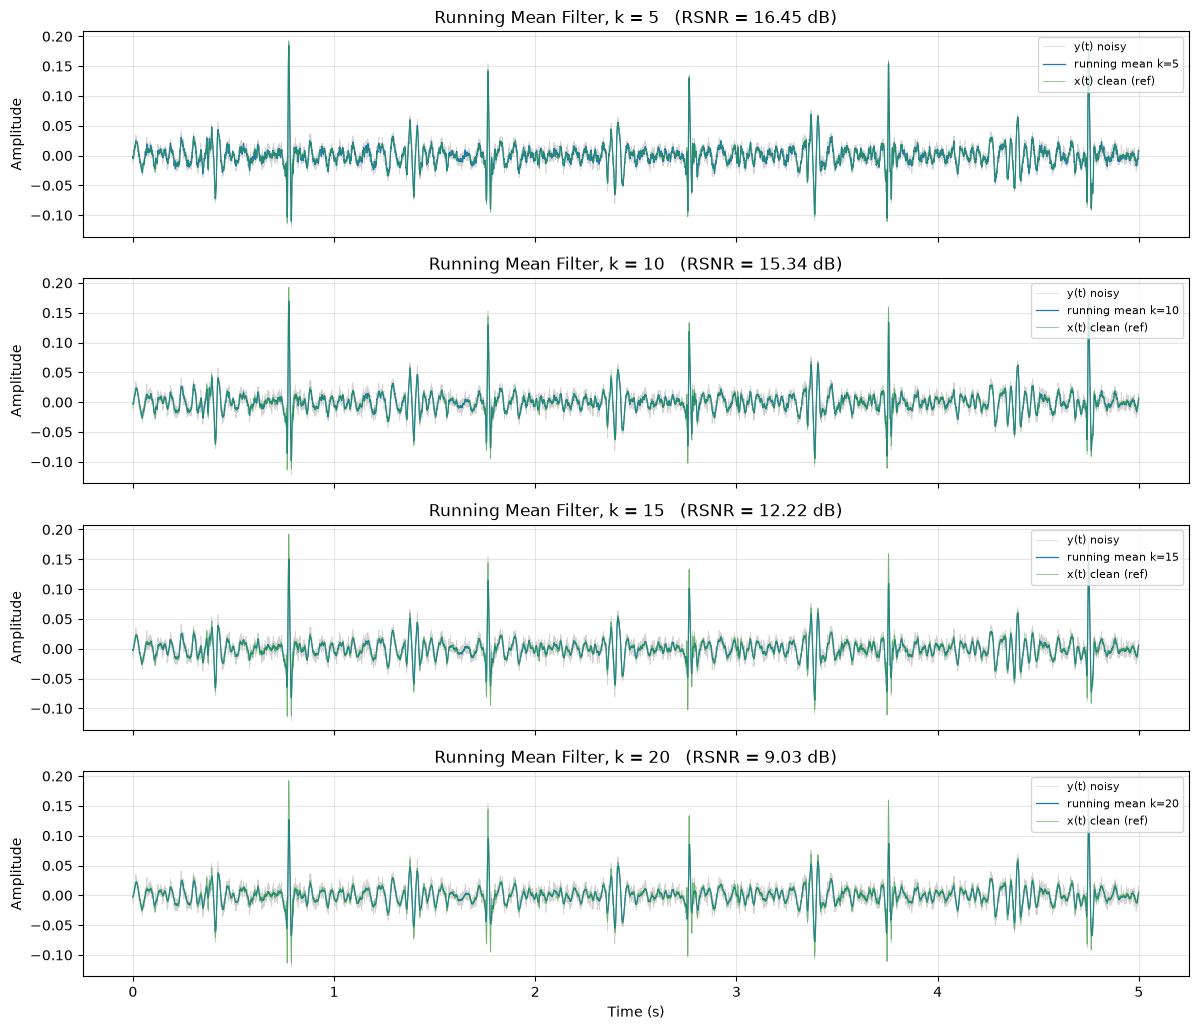

In [ ]:
# ---------------------------------------------------------------- #
# Task ii: Running Mean Filter on y(t) for k = 5, 10, 15, 20
# filtSig = mean over window of length k (centered), via uniform_filter1d
# ---------------------------------------------------------------- #
k_values = [5, 10, 15, 20]

def running_mean(sig, k):
    # 'nearest' mode keeps edges defined; center the window
    return uniform_filter1d(sig, size=k, mode='nearest')

filt_results = {}
fig, axes = plt.subplots(len(k_values), 1, figsize=(12, 2.6*len(k_values)), sharex=True)
for i, k in enumerate(k_values):
    f = running_mean(y, k)
    filt_results[k] = f
    print('k = %2d  RSNR = %7.2f dB' % (k, rsnr_db(x, f)))
    ax = axes[i]
    ax.plot(t, y, color='lightgray', lw=0.5, label='y(t) noisy')
    ax.plot(t, f, color='tab:blue', lw=0.9, label='running mean k=%d' % k)
    ax.plot(t, x, color='tab:green', lw=0.6, alpha=0.6, label='x(t) clean (ref)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Running Mean Filter, k = %d   (RSNR = %.2f dB)' % (k, rsnr_db(x, f)))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


sigma =  4  RSNR =   13.84 dB
sigma =  6  RSNR =    9.95 dB
sigma =  8  RSNR =    7.44 dB
sigma = 10  RSNR =    5.73 dB


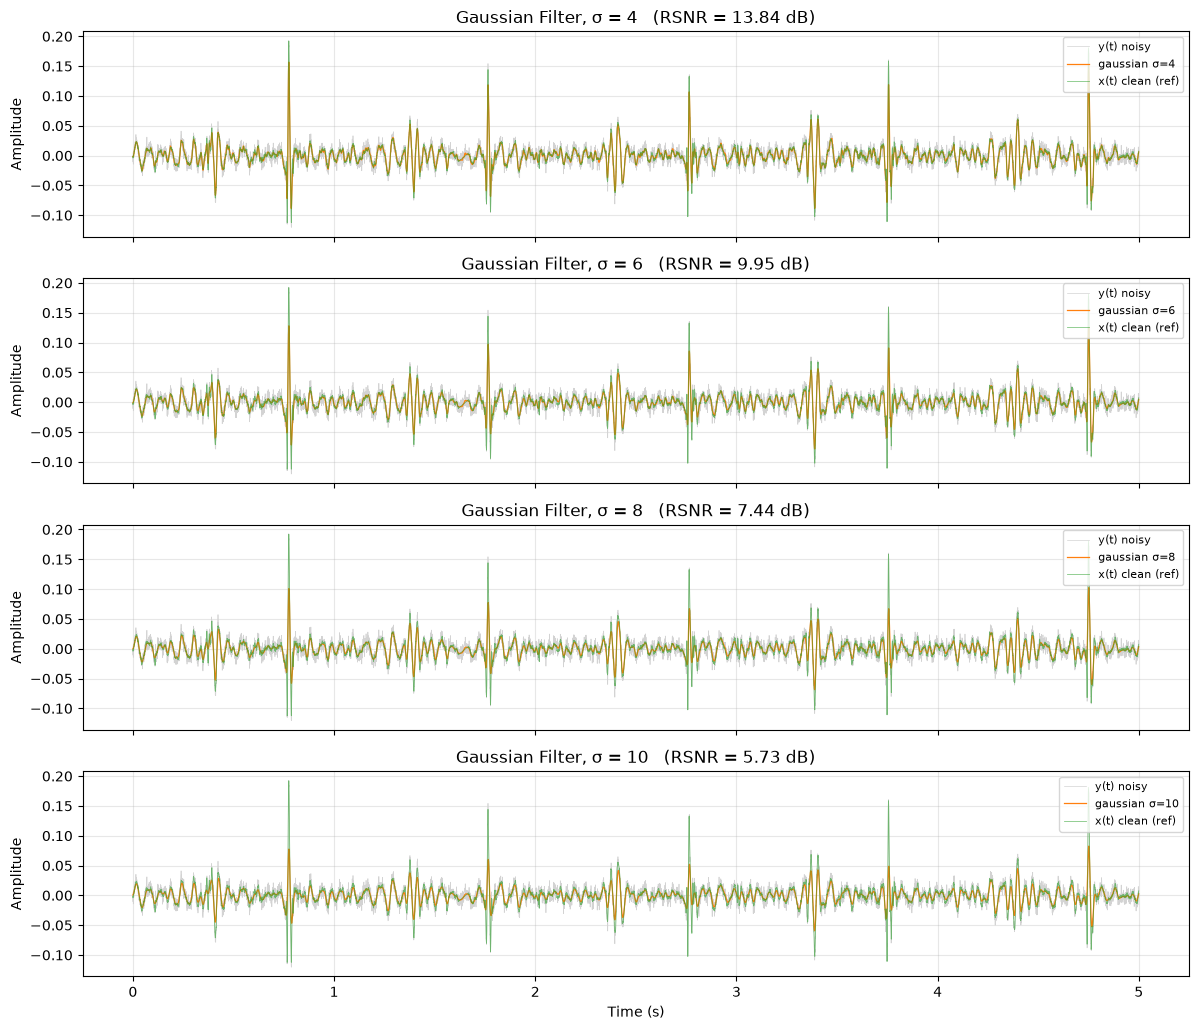

In [ ]:
# ---------------------------------------------------------------- #
# Task iii: Gaussian Filter on y(t) for sigma = 4, 6, 8, 10
# smoothSignal = gaussian-kernel convolution
# ---------------------------------------------------------------- #
sigma_values = [4, 6, 8, 10]

def gaussian_filter(sig, sigma):
    # build a kernel sized ~ 8*sigma + 1, normalized
    radius = max(1, int(4 * sigma))
    kernel = gaussian(2 * radius + 1, sigma)
    kernel = kernel / kernel.sum()
    return convolve1d(sig, kernel, mode='nearest')

gauss_results = {}
fig, axes = plt.subplots(len(sigma_values), 1, figsize=(12, 2.6*len(sigma_values)), sharex=True)
for i, s in enumerate(sigma_values):
    sm = gaussian_filter(y, s)
    gauss_results[s] = sm
    print('sigma = %2d  RSNR = %7.2f dB' % (s, rsnr_db(x, sm)))
    ax = axes[i]
    ax.plot(t, y, color='lightgray', lw=0.5, label='y(t) noisy')
    ax.plot(t, sm, color='tab:orange', lw=0.9, label='gaussian σ=%d' % s)
    ax.plot(t, x, color='tab:green', lw=0.6, alpha=0.6, label='x(t) clean (ref)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Gaussian Filter, σ = %d   (RSNR = %.2f dB)' % (s, rsnr_db(x, sm)))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


order n = 11  RSNR =   16.05 dB
order n = 21  RSNR =   10.41 dB
order n = 31  RSNR =    6.45 dB
order n = 41  RSNR =    3.85 dB


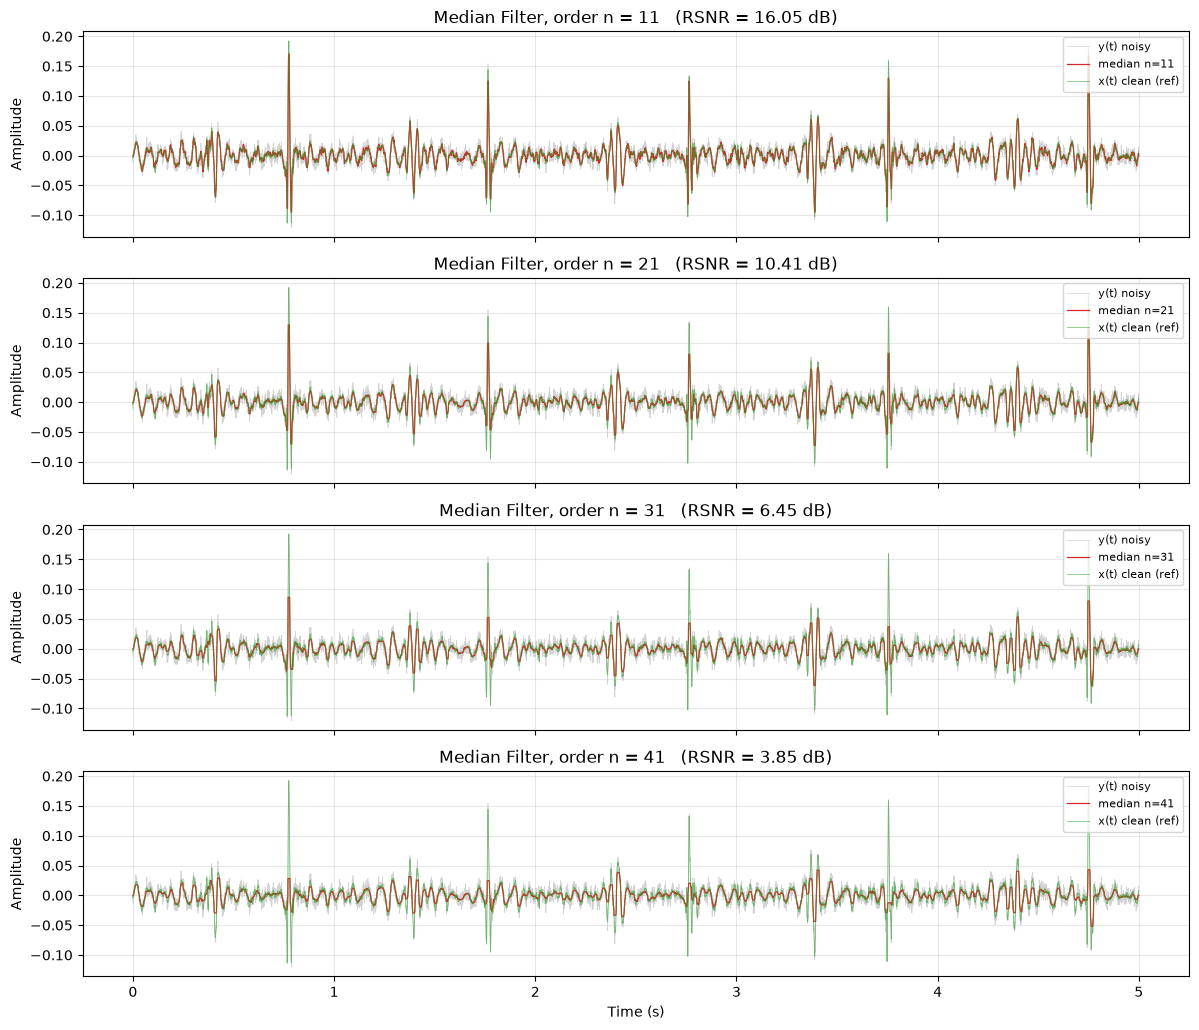

In [ ]:
# ---------------------------------------------------------------- #
# Task iv: Median Filter on y(t) for order n = 11, 21, 31, 41
# cleanSignal = median over window of length n (must be odd)
# ---------------------------------------------------------------- #
median_orders = [11, 21, 31, 41]

median_results = {}
fig, axes = plt.subplots(len(median_orders), 1, figsize=(12, 2.6*len(median_orders)), sharex=True)
for i, n in enumerate(median_orders):
    cl = medfilt(y, kernel_size=n)
    median_results[n] = cl
    print('order n = %2d  RSNR = %7.2f dB' % (n, rsnr_db(x, cl)))
    ax = axes[i]
    ax.plot(t, y, color='lightgray', lw=0.5, label='y(t) noisy')
    ax.plot(t, cl, color='tab:red', lw=0.9, label='median n=%d' % n)
    ax.plot(t, x, color='tab:green', lw=0.6, alpha=0.6, label='x(t) clean (ref)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Median Filter, order n = %d   (RSNR = %.2f dB)' % (n, rsnr_db(x, cl)))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


window =    hamming  RSNR =    5.07 dB
window =       hann  RSNR =    5.07 dB
window =   blackman  RSNR =    5.59 dB
window =   bartlett  RSNR =    5.65 dB


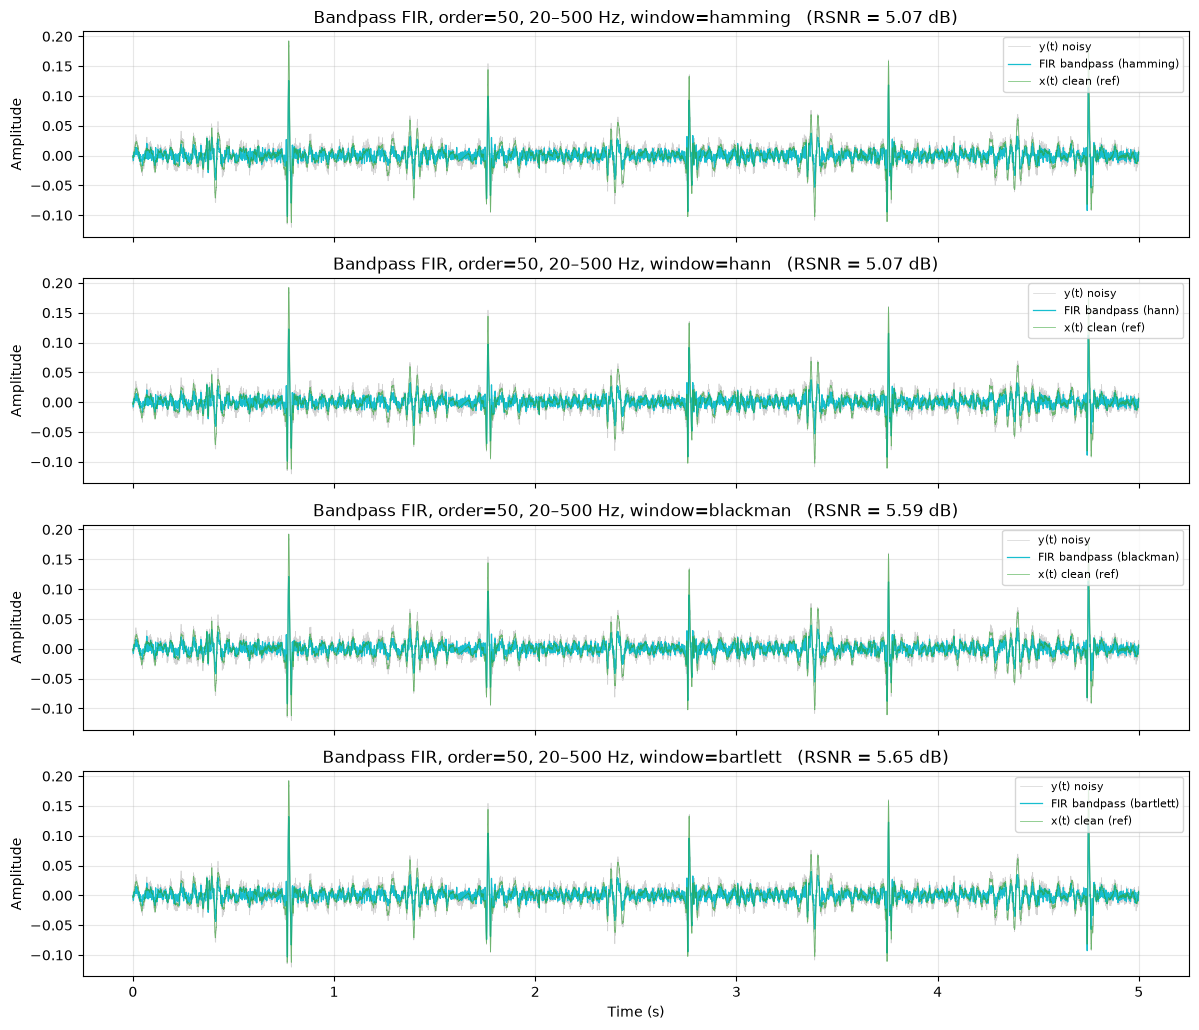

In [ ]:
# ---------------------------------------------------------------- #
# Task v: Bandpass FIR filter, order 50, passband 20–500 Hz
# windows: hamming, hann, blackman, bartlett; zero-phase via filtfilt
# ---------------------------------------------------------------- #
nyq = fs / 2.0
low, high = 20.0, 500.0
fir_order = 50
windows = ['hamming', 'hann', 'blackman', 'bartlett']

fir_results = {}
fig, axes = plt.subplots(len(windows), 1, figsize=(12, 2.6*len(windows)), sharex=True)
for i, win in enumerate(windows):
    # firwin: normalized cutoff frequencies (0 to 1 where 1 = Nyquist)
    taps = firwin(numtaps=fir_order + 1, cutoff=[low / nyq, high / nyq],
                  pass_zero=False, window=win, scale=True)
    f = filtfilt(taps, 1.0, y)
    fir_results[win] = f
    print('window = %10s  RSNR = %7.2f dB' % (win, rsnr_db(x, f)))
    ax = axes[i]
    ax.plot(t, y, color='lightgray', lw=0.5, label='y(t) noisy')
    ax.plot(t, f, color='tab:cyan', lw=0.9, label='FIR bandpass (%s)' % win)
    ax.plot(t, x, color='tab:green', lw=0.6, alpha=0.6, label='x(t) clean (ref)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Bandpass FIR, order=%d, 20–500 Hz, window=%s   (RSNR = %.2f dB)'
                 % (fir_order, win, rsnr_db(x, f)))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


Butterworth order = 4  RSNR =    7.13 dB
Butterworth order = 6  RSNR =    6.82 dB
Butterworth order = 8  RSNR =    6.67 dB
Butterworth order = 10  RSNR =    6.58 dB


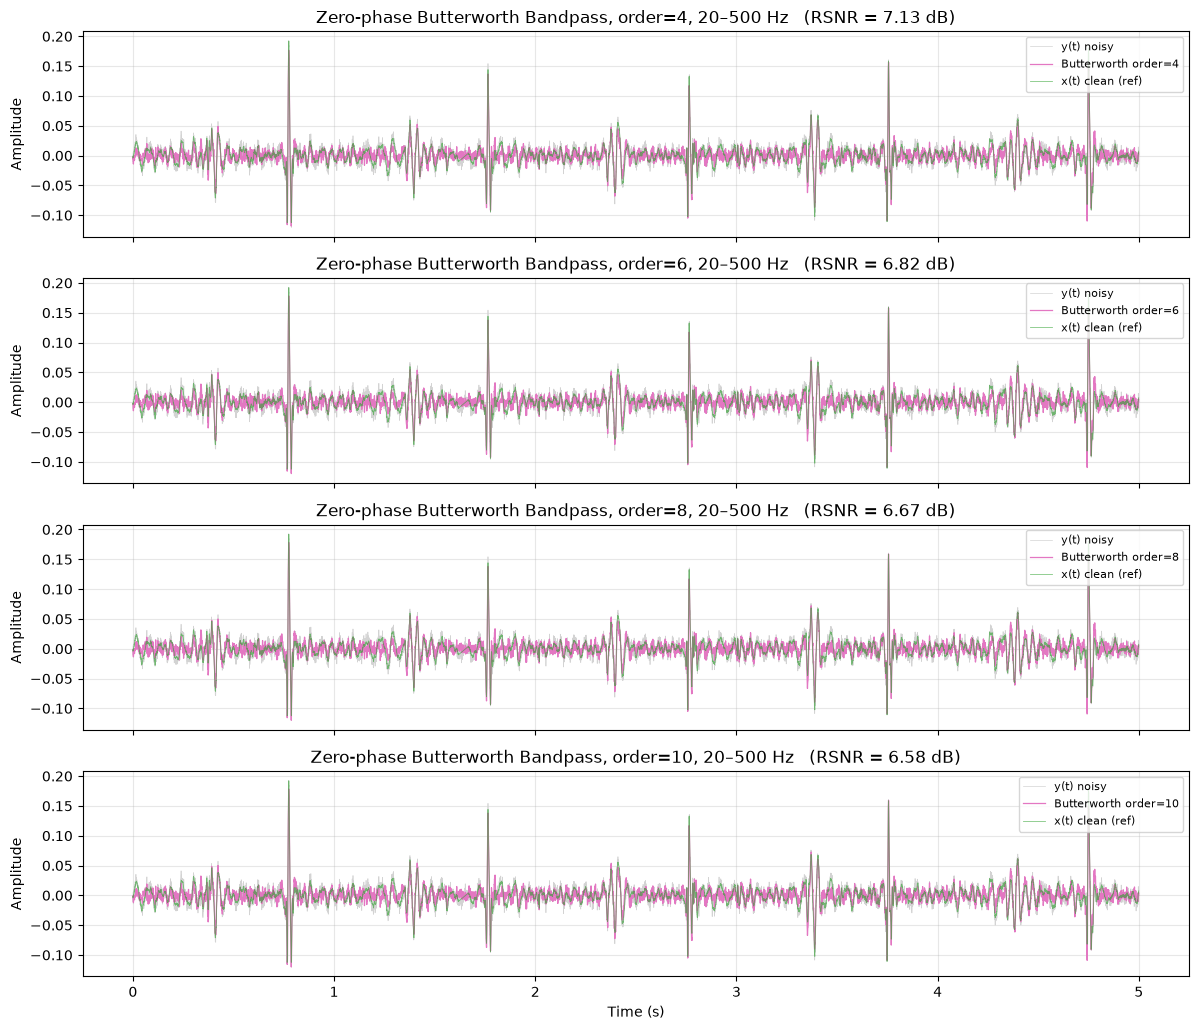

In [ ]:
# ---------------------------------------------------------------- #
# Task vi: Zero-phase Butterworth bandpass filter on y(t)
# orders = 4, 6, 8, 10; passband 20–500 Hz; sosfiltfilt (zero-phase)
# ---------------------------------------------------------------- #
butter_orders = [4, 6, 8, 10]

butter_results = {}
fig, axes = plt.subplots(len(butter_orders), 1, figsize=(12, 2.6*len(butter_orders)), sharex=True)
for i, order in enumerate(butter_orders):
    sos = butter(N=order, Wn=[low / nyq, high / nyq], btype='band',
                 analog=False, output='sos')
    f = sosfiltfilt(sos, y)
    butter_results[order] = f
    print('Butterworth order = %d  RSNR = %7.2f dB' % (order, rsnr_db(x, f)))
    ax = axes[i]
    ax.plot(t, y, color='lightgray', lw=0.5, label='y(t) noisy')
    ax.plot(t, f, color='tab:pink', lw=0.9, label='Butterworth order=%d' % order)
    ax.plot(t, x, color='tab:green', lw=0.6, alpha=0.6, label='x(t) clean (ref)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Zero-phase Butterworth Bandpass, order=%d, 20–500 Hz   (RSNR = %.2f dB)'
                 % (order, rsnr_db(x, f)))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


In [ ]:
# ---------------------------------------------------------------- #
# Task vii: Repeat all steps for SNR = 5, 10, 15 dB
# Task viii: Compute RSNR for each filter/case and tabulate
# ---------------------------------------------------------------- #
snr_levels = [5, 10, 15]

# Collect results per SNR level
all_results = {}   # snr -> {filter_name: (params_str, rsnr)}

for snr in snr_levels:
    y_s, w_s = add_white_gaussian_noise(x, snr, seed=100 + snr)
    row = {}
    # running mean
    for k in k_values:
        row['Running Mean k=%d' % k] = ('k=%d' % k, rsnr_db(x, running_mean(y_s, k)))
    # gaussian
    for s in sigma_values:
        row['Gaussian σ=%d' % s] = ('σ=%d' % s, rsnr_db(x, gaussian_filter(y_s, s)))
    # median
    for n in median_orders:
        row['Median n=%d' % n] = ('n=%d' % n, rsnr_db(x, medfilt(y_s, kernel_size=n)))
    # FIR windows
    for win in windows:
        taps = firwin(numtaps=fir_order + 1, cutoff=[low / nyq, high / nyq],
                      pass_zero=False, window=win, scale=True)
        row['FIR %s' % win] = ('order=%d' % fir_order, rsnr_db(x, filtfilt(taps, 1.0, y_s)))
    # butterworth
    for order in butter_orders:
        sos = butter(N=order, Wn=[low / nyq, high / nyq], btype='band',
                     analog=False, output='sos')
        row['Butterworth ord=%d' % order] = ('order=%d' % order, rsnr_db(x, sosfiltfilt(sos, y_s)))
    all_results[snr] = row

# Build a summary table (HTML)
def fmt(v):
    return 'inf' if v == np.inf else '%.2f' % v

filter_names = list(all_results[snr_levels[0]].keys())
html = ['<table border="1" cellpadding="6" cellspacing="0">',
        '<tr><th>Filter</th><th>Param</th>' +
        ''.join('<th>SNR %d dB</th>' % s for s in snr_levels) + '</tr>']
for name in filter_names:
    param = all_results[snr_levels[0]][name][0]
    html.append('<tr><td><b>%s</b></td><td>%s</td>' % (name, param))
    for s in snr_levels:
        html.append('<td>%s dB</td>' % fmt(all_results[s][name][1]))
    html.append('</tr>')
html.append('</table>')
display(HTML('<h3>Reconstruction SNR (RSNR) summary — original x(t) vs filtered y(t)</h3>' + ''.join(html)))

print()
print('Higher RSNR = better reconstruction of x(t).')
print('Note: FIR/Butterworth bandpass (20–500 Hz) generally preserves the PCG')
print('      heart-sound band best, while heavy smoothing blurs S1/S2 components.')


Filter,Param,SNR 5 dB,SNR 10 dB,SNR 15 dB
Running Mean k=5,k=5,11.84 dB,16.41 dB,20.59 dB
Running Mean k=10,k=10,12.94 dB,15.25 dB,16.63 dB
Running Mean k=15,k=15,11.32 dB,12.21 dB,12.57 dB
Running Mean k=20,k=20,8.69 dB,9.03 dB,9.17 dB
Gaussian σ=4,σ=4,12.48 dB,13.78 dB,14.38 dB
Gaussian σ=6,σ=6,9.54 dB,9.93 dB,10.08 dB
Gaussian σ=8,σ=8,7.25 dB,7.42 dB,7.48 dB
Gaussian σ=10,σ=10,5.60 dB,5.70 dB,5.74 dB
Median n=11,n=11,12.45 dB,15.81 dB,18.19 dB
Median n=21,n=21,9.64 dB,10.29 dB,10.68 dB



Higher RSNR = better reconstruction of x(t).
Note: FIR/Butterworth bandpass (20–500 Hz) generally preserves the PCG
      heart-sound band best, while heavy smoothing blurs S1/S2 components.
